# Root-finding

**Lecture 7 · Wednesday, 28 October 2026 · Notebook 1 of 2**

**Optimization:** find the best feasible choice. **Root-finding:** find an input that makes an equation hold.

Today we start with a small market: **at what price does quantity demanded equal quantity supplied?** We explain the economics before the code. The numbers are illustrative, not real market estimates.

This notebook contains **Videos 7A and 7B**. Video 7C uses `02_Interpolation.ipynb`.

## How to work

| Recording | Material |
| --- | --- |
| Video 7A: Equilibrium, a known answer and bisection | Sections 1–2 here |
| Video 7B: SciPy, Newton and checking a root | Sections 3–5 here |
| Video 7C: Interpolation, and solving without a formula | `02_Interpolation.ipynb` |

**Before class (Tuesday, 23:59):** after the videos, solve warm-ups **W1–W2** in `Exercises.ipynb`, enter your answers in the Absalon quiz and upload the notebook with your code. Class (Wednesday 4 November, together with Lecture 8) starts with the most common mistakes.

**Reuse from Lectures 1–6:** functions, arrays, loops, conditionals, plotting, a known answer as a test, and passing a function to SciPy. **New:** residual, bracket, bisection and Newton steps.

**Table of contents**<a id='toc0_'></a>
- 1. [Turn market equilibrium into an equation](#toc1_)
- 2. [Bisection: keep the half with a sign change](#toc2_)
- 3. [Use SciPy and check the residual](#toc3_)
- 4. [Newton: use the slope](#toc4_)
- 5. [Choose a method and summarise](#toc5_)
- 6. [Optional: the link to Lecture 6](#toc6_)

<a id='video-7a'></a>
> **Start Video 7A**  
> Question: what number should be zero at a market equilibrium?

## 1. <a id='toc1_'></a>[Turn market equilibrium into an equation](#toc0_)

At price $p$, buyers would like to buy $Q^D(p)$ units and sellers would like to sell $Q^S(p)$ units. Our toy market has

$$Q^D(p)=120-10p,\qquad Q^S(p)=20+5p^2.$$

We only consider prices **between 0 and 8**, where both quantities are nonnegative. Quantities are units per period; price is money per unit.

A higher price reduces demand and increases supply in this example. **Market equilibrium** means that the two quantities are equal:

$$Q^D(p)=Q^S(p).$$

Bring everything to one side. Define **excess demand** as

$$f(p)=Q^D(p)-Q^S(p).$$

Now the task is **find a price $p$ such that $f(p)=0$**. This is a root-finding problem, not a maximization problem.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize

In [2]:
def demand(p):
    """Quantity buyers want at price p; use 0 <= p <= 8."""
    return 120.0 - 10.0*p


def supply(p):
    """Quantity sellers offer at price p."""
    return 20.0 + 5.0*p**2


def excess_demand(p):
    return demand(p) - supply(p)

### The sign tells us where to look

Positive excess demand means buyers want more than sellers offer. Negative excess demand means sellers offer more than buyers want. The **residual** is the value of `excess_demand` at a proposed price: it measures how far the equation is from being satisfied, in **quantity units**.

In [3]:
for p in [0.0, 2.0, 4.0, 6.0, 8.0]:
    print(f'p = {p:4.1f}; demand = {demand(p):6.1f}; '
          f'supply = {supply(p):6.1f}; residual = {excess_demand(p):7.1f}')

p =  0.0; demand =  120.0; supply =   20.0; residual =   100.0
p =  2.0; demand =  100.0; supply =   40.0; residual =    60.0
p =  4.0; demand =   80.0; supply =  100.0; residual =   -20.0
p =  6.0; demand =   60.0; supply =  200.0; residual =  -140.0
p =  8.0; demand =   40.0; supply =  340.0; residual =  -300.0


### Plot the two sides

We put **price on the horizontal axis** because it is the input to our Python functions. This is a computational plot; the axis convention differs from the usual introductory supply–demand diagram.

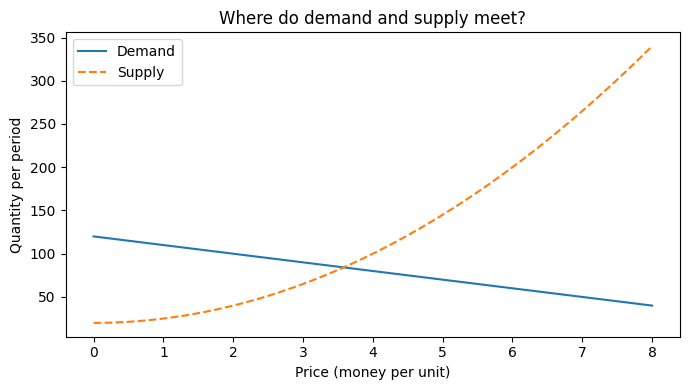

In [4]:
price_grid = np.linspace(0.0, 8.0, 150)

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
ax.plot(price_grid, demand(price_grid), label='Demand')
ax.plot(price_grid, supply(price_grid), linestyle='--', label='Supply')
ax.set_xlabel('Price (money per unit)')
ax.set_ylabel('Quantity per period')
ax.set_title('Where do demand and supply meet?')
ax.legend()
fig.tight_layout()
plt.show()

### A known answer helps us test our code

This market is simple enough to solve by hand. Setting $f(p)=100-10p-5p^2=0$ is the same as $p^2+2p-20=0$, and the quadratic formula gives

$$p^*=-1+\sqrt{21}\approx 3.583.$$

The other solution, $-1-\sqrt{21}$, is negative and therefore not a price. As in Lecture 6, we use the known answer only to **test** the numerical methods. Once demand is known only from a table (Video 7C), no such formula exists.

In [5]:
p_true = -1.0 + np.sqrt(21.0)

print(f'Benchmark price: {p_true:.6f}')
print(f'Residual at the benchmark: {excess_demand(p_true):.2e}')

Benchmark price: 3.582576
Residual at the benchmark: 1.42e-14


## 2. <a id='toc2_'></a>[Bisection: keep the half with a sign change](#toc0_)

A **bracket** is an interval with endpoints `a` and `b`. If a function is continuous and its endpoint values have **opposite signs**, there is at least one root between them. If an endpoint itself has value zero, we have already found a root.

For this market, `[0, 8]` is a valid bracket. Demand falls while supply rises, so excess demand is strictly decreasing on this interval: **this example has only one equilibrium**. A sign change alone does not prove uniqueness in other problems.

**Bisection** repeatedly cuts a bracket in half:

1. Calculate the midpoint, `m = (a + b)/2`.
2. Evaluate the function at `m`.
3. Keep the half whose endpoints still have opposite signs.

Each cut halves the price interval. We need function values, not a derivative.

**Pause and predict:** at the midpoint $p=4$ of the bracket $[0, 8]$, is excess demand positive or negative? Which half do we keep?

In [6]:
a = 0.0
b = 8.0
m = (a + b)/2

print('At the left endpoint:', excess_demand(a))
print('At the midpoint:', excess_demand(m))
print('At the right endpoint:', excess_demand(b))

At the left endpoint: 100.0
At the midpoint: -20.0
At the right endpoint: -300.0


### Watch four iterations

This loop is a **four-step demonstration**, not a complete general-purpose solver. We reset the bracket to `[0, 8]` so it does not depend on your task. The `== 0` branch handles the special case of landing exactly on a root; otherwise we retain a sign change.

In [7]:
a = 0.0
b = 8.0

print('Step       a       b       m     residual at m')
for step in range(1, 5):
    m = (a + b)/2
    fm = excess_demand(m)
    print(f'{step:4d} {a:7.3f} {b:7.3f} {m:7.3f} {fm:17.4f}')

    if fm == 0.0:
        a = m
        b = m
        break
    elif excess_demand(a)*fm < 0.0:       # opposite signs at a and m: the root is in [a, m]
        b = m
    else:
        a = m

print(f'Remaining bracket: [{a:.4f}, {b:.4f}]')
print(f'Bracket width: {b - a:.4f} price units')
print(f'Benchmark {p_true:.4f} inside the bracket:', a <= p_true <= b)

Step       a       b       m     residual at m
   1   0.000   8.000   4.000          -20.0000
   2   0.000   4.000   2.000           60.0000
   3   2.000   4.000   3.000           25.0000
   4   3.000   4.000   3.500            3.7500
Remaining bracket: [3.5000, 4.0000]
Bracket width: 0.5000 price units
Benchmark 3.5826 inside the bracket: True


**When should a real algorithm stop?** A tiny price interval makes the price precise; a tiny residual makes demand and supply nearly equal. Those are **different quantities with different units**. In practice we also need an iteration limit. SciPy handles the iteration and stopping rules for us next.

**A limitation:** without continuity, a sign change can be a jump rather than a zero. And a function can touch zero without changing sign. Our bracketing argument needs its stated assumptions.

> **Stop Video 7A.** You should be able to turn an equality into a residual and explain which half of a bracket is retained.

<a id='video-7b'></a>
> **Start Video 7B**  
> In a fresh kernel, run Sections 1–2 first. Question: how do we obtain a root and decide whether to trust it?

## 3. <a id='toc3_'></a>[Use SciPy and check the residual](#toc0_)

`root_scalar` solves **one equation in one unknown**. We pass the function, not an already calculated residual. A bracket supplies two endpoints; it is not a list of all trial prices.

First use bisection. `xtol` is an absolute tolerance **in price units**, not in quantity units.

In [8]:
result_bisect = optimize.root_scalar(
    excess_demand,
    bracket=[0.0, 8.0],
    method='bisect',
    xtol=1e-8
)

print('Converged:', result_bisect.converged)
print('Status:', result_bisect.flag)
if not result_bisect.converged:
    raise RuntimeError(result_bisect.flag)

p_bisect = result_bisect.root
print(f'Price: {p_bisect:.6f}')
print(f'Demand: {demand(p_bisect):.6f}')
print(f'Supply: {supply(p_bisect):.6f}')
print(f'Residual: {excess_demand(p_bisect):.3e}')
print(f'Error vs benchmark: {abs(p_bisect - p_true):.1e}')

Converged: True
Status: converged
Price: 3.582576
Demand: 84.174243
Supply: 84.174243
Residual: -2.851e-07
Error vs benchmark: 6.2e-09


### Brent's method: the same bracket, another method

`brentq` combines bracketing with faster trial-point rules. It is a useful first choice **when a continuous scalar function has a valid sign-changing bracket**. It is not a method for every possible equation.

The interface is almost unchanged:

In [9]:
result_brent = optimize.root_scalar(
    excess_demand,
    bracket=[0.0, 8.0],
    method='brentq',
    xtol=1e-8
)

print('Converged:', result_brent.converged)
if not result_brent.converged:
    raise RuntimeError(result_brent.flag)

p_star = result_brent.root
print(f'Price: {p_star:.6f}')
print(f'Absolute residual: {abs(excess_demand(p_star)):.3e}')
print(f'Error vs benchmark: {abs(p_star - p_true):.1e}')
print('Bisection iterations:', result_bisect.iterations)
print('Brent iterations:', result_brent.iterations)

Converged: True
Price: 3.582576
Absolute residual: 2.402e-11
Error vs benchmark: 5.2e-13
Bisection iterations: 30
Brent iterations: 9


**Effort:** as in Lecture 6, count the work. Both methods reach the benchmark, but Brent needs far fewer steps than halving the bracket every time.

<details>
<summary><strong>Code reminder: result fields</strong></summary>

For `minimize_scalar`, the answer was `.x` and the status was `.success`. For `root_scalar`, they are **`.root`** and **`.converged`**.

Extra inputs of your function go in `args=(...)`, exactly as in Lecture 6.

A root-finding result does not have a `.fun` residual field. Evaluate your original function at `.root` to check it.

</details>

## 4. <a id='toc4_'></a>[Newton: use the slope](#toc0_)

Newton's method takes a different approach. At a trial price, draw a straight line with the function's current slope (the tangent). Use the point where that line crosses zero as the next guess:

$$p_{\mathrm{new}}=p_{\mathrm{old}}-\frac{f(p_{\mathrm{old}})}{f'(p_{\mathrm{old}})},\qquad f'(p)=-10-10p \text{ in our market.}$$

One step makes the **tangent** zero, not the original function. The solver repeats the step from the new guess.

Old guess: 7.0000; one Newton step: 4.3125; residual there: -36.11


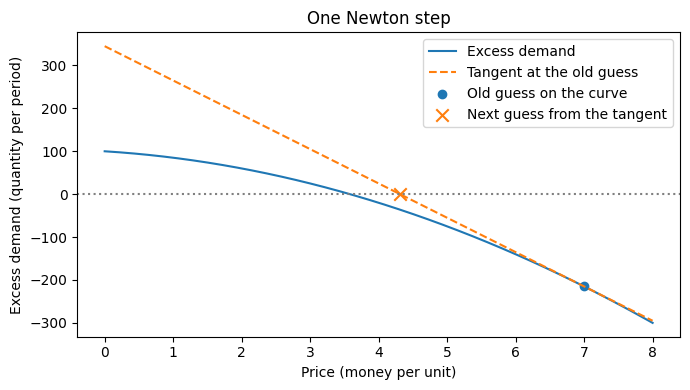

In [10]:
def excess_demand_derivative(p):
    return -10.0 - 10.0*p


# a. one Newton step from p = 7
p_old = 7.0
p_new = p_old - excess_demand(p_old)/excess_demand_derivative(p_old)
print(f'Old guess: {p_old:.4f}; one Newton step: {p_new:.4f}; residual there: {excess_demand(p_new):.2f}')

# b. picture of the step
tangent = excess_demand(p_old) + excess_demand_derivative(p_old)*(price_grid - p_old)

fig = plt.figure(figsize=(7, 4))
ax = fig.add_subplot(1, 1, 1)
ax.plot(price_grid, excess_demand(price_grid), label='Excess demand')
ax.plot(price_grid, tangent, linestyle='--', label='Tangent at the old guess')
ax.axhline(0.0, linestyle=':', color='grey')
ax.scatter(p_old, excess_demand(p_old), marker='o', label='Old guess on the curve')
ax.scatter(p_new, 0.0, marker='x', s=80, label='Next guess from the tangent')
ax.set_xlabel('Price (money per unit)')
ax.set_ylabel('Excess demand (quantity per period)')
ax.set_title('One Newton step')
ax.legend()
fig.tight_layout()
plt.show()

### Let SciPy repeat the Newton step

We supply `fprime` explicitly so the derivative used is visible. Unlike the bracketed calls above, `x0` is **one initial guess**, not a pair of endpoints.

In [11]:
result_newton = optimize.root_scalar(
    excess_demand,
    x0=7.0,
    fprime=excess_demand_derivative,     # the slope *function*, not a number
    method='newton',
    xtol=1e-8,
    maxiter=50
)

print('Converged:', result_newton.converged)
if not result_newton.converged:
    raise RuntimeError(result_newton.flag)

p_newton = result_newton.root
print(f'Price: {p_newton:.6f}')
print('Inside the economic domain:', 0.0 <= p_newton <= 8.0)
print(f'Absolute residual: {abs(excess_demand(p_newton)):.3e}')

Converged: True
Price: 3.582576
Inside the economic domain: True
Absolute residual: 2.842e-14


### A careless starting guess

Newton only needs a starting guess, not a bracket, so nothing keeps it inside the economic domain.

**Pause and predict:** where does Newton end if we start at $p=-2$?

In [12]:
result_far = optimize.root_scalar(
    excess_demand,
    x0=-2.0,
    fprime=excess_demand_derivative,
    method='newton'
)

p_far = result_far.root
print('Converged:', result_far.converged)
print(f'Price: {p_far:.6f}; absolute residual: {abs(excess_demand(p_far)):.1e}')
print('Inside the economic domain:', 0.0 <= p_far <= 8.0)

Converged: True
Price: -5.582576; absolute residual: 2.8e-14
Inside the economic domain: False


The solver converged, and the residual is tiny: $-1-\sqrt{21}$ really solves the equation. But a negative price is not a market equilibrium. **An equation can have several roots; the economics decides which one we want.** A bracket inside the domain, as with `brentq`, rules this out.

## 5. <a id='toc5_'></a>[Choose a method and summarise](#toc0_)

| Method | What you supply | What to remember |
| --- | --- | --- |
| Bisection | A continuous function and valid bracket | Repeatedly halve the interval; safe but many steps |
| Brent (`brentq`) | A continuous function and valid bracket | Keeps the bracket's safety with far fewer steps: a good first choice |
| Newton | A function, starting guess and a slope | Fast nearby, but can find a root outside the domain |

**Always check:** solver status, the economic domain and the residual in the **original** equation. Small steps by themselves are not proof that the equation holds. With several roots, different starting points or brackets can select different roots.

**Keep the questions separate:** an equilibrium equation asks whether two sides match; an optimization asks which feasible choice is best.

Next: sometimes we know a function only at a few points. Open **`02_Interpolation.ipynb`** for Video 7C.

> **Stop Video 7B.** The following link to Lecture 6 is optional reading.

## 6. <a id='toc6_'></a>[Optional: the link to Lecture 6](#toc0_)

**Optional reading, not part of the videos or the class.** The Lecture 6 consumer's optimum can also be found as a root. For an interior Cobb–Douglas choice, the best $x_1$ satisfies the first-order condition

$$g(x_1)=\frac{\alpha}{x_1}-\frac{(1-\alpha)p_1}{I-p_1x_1}=0,\qquad 0<x_1<I/p_1.$$

It says: the gain from a little more of good 1 equals the loss from having less money for good 2. The condition is supplied, not derived. We keep the bracket away from the endpoints, where the denominators are zero.

In [13]:
alpha = 0.5
I = 10.0
p1 = 1.0
p2 = 2.0


def consumer_foc(x1):
    return alpha/x1 - (1 - alpha)*p1/(I - p1*x1)


consumer_result = optimize.root_scalar(
    consumer_foc,
    bracket=[0.01*I/p1, 0.99*I/p1],
    method='brentq'
)

print('Converged:', consumer_result.converged)
if not consumer_result.converged:
    raise RuntimeError(consumer_result.flag)

consumer_x1 = consumer_result.root
consumer_x2 = (I - p1*consumer_x1)/p2
print(f'Bundle: ({consumer_x1:.6f}, {consumer_x2:.6f})')
print(f'First-order-condition residual: {consumer_foc(consumer_x1):.3e}')

Converged: True
Bundle: (5.000000, 2.500000)
First-order-condition residual: 3.469e-16


### References

[SciPy root_scalar](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.root_scalar.html) and its [Newton option](https://docs.scipy.org/doc/scipy/reference/optimize.root_scalar-newton.html). Without `fprime`, `method='newton'` is not the same as the [secant method](https://docs.scipy.org/doc/scipy/reference/optimize.root_scalar-secant.html) selected explicitly.